In [1]:

import math
import numpy as np
from scipy.optimize import brentq

# ------------------------------------------------------------------ constants
R = 8.314462            # J/(mol K), universal gas constant
Rs = 287.0              # J/(kg K), specific gas constant of air
pi = math.pi
Ma, Mw = 0.028964, 0.018015          # kg/mol  dry air, water
Cv_a = 2.5 * R                       # J/(mol K)
Cp_v = 1864.0 * Mw                   # J/(mol K)  vapour cp
Cv_v = Cp_v - R                      # J/(mol K)  vapour cv
c_l = 4182.0 * Mw                    # J/(mol K)  liquid water
Lv298 = 43.99e3                      # J/mol at 298.15 K
T_REF = 303.15                       # reference temperature of the internal energy
RHO_W = 0.997                        # kg/L
G_COEF = 3.0                         # steady parabolic profile between the sheets

DEFAULTS = dict(
    # ambient and operating point
    T0=303.15, RH=0.7, P_atm=101325.0,   # ambient temperature [K], relative humidity, total pressure [Pa]
    dT_s=2.0,                           # heat sink temperature minus ambient temperature [K]
    comp=0.65,                           # compression 1 - V1/V0
    dT=4.0,                             # gas stays within +-dT/2 of the sink (compression)
    dT_exp_factor=0.833,                # expansion uses dT * dT_exp_factor (0.833 equalizes the strokes at the default settings)
    t_pause=5.0,                        # dwell at maximum compression [s]
    eff=0.98,                           # force-transfer efficiency applied to the expansion work
    # geometry
    r=0.25, sheet_l=0.8,             # piston radius [m], length of each sheet set [m]
    gap=5e-3, sheet_t=2e-3,             # gap between same-set sheets [m], sheet thickness [m]
    # transport
    k_gas=0.026,                        # gas thermal conductivity [W/m/K]
    leak_h=30e-6, leak_w=0.40, leak_mu=1.85e-5,   # effective radial clearance, seal length, viscosity
    # numerics
    N=4000, N_pause=800,                # steps per stroke / per pause
    v_max=2.5,                          # maximum piston speed [m/s]  (sets the minimum step time)
)


# ----------------------------------------------------------------- geometry
def gas_V0(p):
    """Gas volume at maximum expansion: the two sheet sets do not overlap, the sheet region is
    2*l tall and gas fills g/(g+t) of it."""
    return pi * p['r'] ** 2 * 2 * p['sheet_l'] * p['gap'] / (p['gap'] + p['sheet_t'])


def vmin_geom(p):
    """V_min/V0 with fully interleaved sheets = (g-t)/(2g); limits the compression."""
    return (p['gap'] - p['sheet_t']) / (2 * p['gap'])


# ------------------------------------------------------------ thermodynamics
def psat(T):
    """Saturation pressure of liquid water, Murphy & Koop (2005) [Pa]."""
    lnT = math.log(T)
    return math.exp(54.842763 - 6763.22 / T - 4.210 * lnT + 0.000367 * T
                    + math.tanh(0.0415 * (T - 218.8))
                    * (53.878 - 1331.22 / T - 9.44523 * lnT + 0.014025 * T))


def Lv(T):
    return Lv298 + (Cp_v - c_l) * (T - 298.15)


def u_l(T):
    return c_l * (T - T_REF)


def u_v(T):                                   # u_v - u_l = Lv - R T
    return u_l(T) + Lv(T) - R * T


def U_tot(T, na, nv, nl):
    return na * Cv_a * (T - T_REF) + nv * u_v(T) + nl * u_l(T)


def split(T, V, nw, eq):
    """Vapour / liquid split of the total water nw at (T, V); eq=False: no phase change."""
    if not eq:
        return nw, 0.0
    nv = min(nw, psat(T) * V / (R * T))
    return nv, nw - nv


def solve_T(Utarget, V, na, nw, eq, Tguess):
    """Temperature at which the internal energy equals Utarget (monotonic -> unique root)."""
    def f(T):
        nv, nl = split(T, V, nw, eq)
        return U_tot(T, na, nv, nl) - Utarget
    lo, hi = Tguess - 5.0, Tguess + 5.0
    while f(lo) > 0:
        lo -= 10.0
    while f(hi) < 0:
        hi += 10.0
    return brentq(f, lo, hi, xtol=1e-10, rtol=1e-13)


def conditions(p):
    """Sink temperature, vapour pressure and relative humidity of the air once it has taken the
    sink temperature.  The air keeps its ambient vapour pressure (and total pressure), so a warmer
    sink means a lower relative humidity."""
    Ts = p['T0'] + p['dT_s']
    Pw0 = p['RH'] * psat(p['T0'])
    return Ts, Pw0 / psat(Ts), Pw0


# ---------------------------------------------------------- transport models
def conductance(p, V):
    """Gas-to-sheet conductance G [W/K] = 3 k V / L^2, L = half gap."""
    return G_COEF * p['k_gas'] * V / (p['gap'] / 2) ** 2


def leakage_kg_per_s(b, h, w, p1, p2, T, mu):
    """Mass leakage through a thin annular gap (isothermal, laminar, compressible).
    b: piston circumference [m]; h: effective radial clearance [m]; w: seal length [m]; p1 > p2 [Pa].
    Eccentricity multiplies the leak rate by up to 2.5, i.e. it acts like a clearance up to 36% larger."""
    return b * h ** 3 * (p1 ** 2 - p2 ** 2) / (24 * mu * Rs * T * w)


def apply_leak(p, na, nw, nv, T, V, dt):
    """Gas lost past the piston during dt, in proportion to the mole fractions.
    Leakage INTO the cylinder (P < P_atm) is not modelled.  Returns na, nw, moles leaked."""
    Patm = p['P_atm']
    P = (na + nv) * R * T / V
    mdot = leakage_kg_per_s(2 * pi * p['r'], p['leak_h'], p['leak_w'], max(P, Patm), Patm,
                            T, p['leak_mu'])
    dn = mdot * dt / ((na * Ma + nv * Mw) / (na + nv))
    xv = nv / (na + nv)
    return na - (1 - xv) * dn, nw - xv * dn, dn


# ------------------------------------------------------------------ one stroke
def run_phase(p, s, V, T, na, nw, nl, eq):
    """One stroke; s=+1 compression, s=-1 expansion.  Returns the new state and records."""
    A = pi * p['r'] ** 2
    dV = p['comp'] * gas_V0(p) / p['N']
    dt_min = dV / (A * p['v_max'])
    Ts, edge = p['Ts'], p['dT'] / 2

    t = W = Qout = leaked = 0.0
    for _ in range(p['N']):
        nv = nw - nl
        Vn = V - s * dV
        Vm = 0.5 * (V + Vn)
        # work from the pressure at the middle of the step
        P = (na + nv) * R * T / V
        Tm = T + s * 0.5 * P * dV / (na * Cv_a + nv * Cv_v + nl * c_l)
        nvm, _ = split(Tm, Vm, nw, eq)
        dW = (na + nvm) * R * Tm / Vm * dV
        # adiabatic update (phase equilibrium and latent heat included)
        T_pre = solve_T(U_tot(T, na, nv, nl) + s * dW, Vn, na, nw, eq, T)
        nvp, nlp = split(T_pre, Vn, nw, eq)
        # heat removal
        G = conductance(p, Vm)
        if s * (T_pre - Ts) <= edge:                # inside the band: minimum time
            dt = dt_min
            Qo = G * (T_pre - Ts) * dt
            T_end = solve_T(U_tot(T_pre, na, nvp, nlp) - Qo, Vn, na, nw, eq, T_pre)
        else:                                       # hold the gas at the band edge
            T_end = Ts + s * edge
            nve, nle = split(T_end, Vn, nw, eq)
            Qo = U_tot(T_pre, na, nvp, nlp) - U_tot(T_end, na, nve, nle)
            dt = max(dt_min, abs(Qo) / (G * edge))
        # leakage
        nv, nl = split(T_end, Vn, nw, eq)
        na, nw, dn = apply_leak(p, na, nw, nv, T_end, Vn, dt)
        nv, nl = split(T_end, Vn, nw, eq)

        V, T = Vn, T_end
        leaked += dn; t += dt; W += dW; Qout += Qo
    return dict(V=V, T=T, na=na, nw=nw, nl=nl, t=t, W=W, Q=Qout, leaked=leaked)


# ----------------------------------------------------------------------- pause
def run_pause(p, V, T, na, nw, nl):
    """Piston held at V for t_pause: the gas relaxes to the sink, leakage continues."""
    G = conductance(p, V)
    n = int(p['N_pause'])
    dt = p['t_pause'] / n
    t = Qo = leaked = 0.0
    for _ in range(n):
        nv = nw - nl
        Q = G * (T - p['Ts']) * dt
        T = solve_T(U_tot(T, na, nv, nl) - Q, V, na, nw, True, T)
        nv, nl = split(T, V, nw, True)
        na, nw, dn = apply_leak(p, na, nw, nv, T, V, dt)
        nv, nl = split(T, V, nw, True)
        t += dt; Qo += Q; leaked += dn
    return dict(V=V, T=T, na=na, nw=nw, nl=nl, t=t, Q=Qo, leaked=leaked)


# --------------------------------------------------------------- full cycle
def simulate(**kw):
    p = {**DEFAULTS, **kw}
    p['Ts'], RH_in, Pw0 = conditions(p)
    A, V0 = pi * p['r'] ** 2, gas_V0(p)
    if p['comp'] > 1 - vmin_geom(p) + 1e-9:
        raise ValueError('comp exceeds the geometric maximum 1-(g-t)/(2g) = %.3f' % (1 - vmin_geom(p)))
    nw0 = Pw0 * V0 / (R * p['Ts'])
    na0 = (p['P_atm'] - Pw0) * V0 / (R * p['Ts'])

    c = run_phase(p, +1, V0, p['Ts'], na0, nw0, 0.0, True)
    z = run_pause(p, c['V'], c['T'], c['na'], c['nw'], c['nl'])
    nl_col = z['nl']                                          # segregated condensate
    p_exp = {**p, 'dT': p['dT'] * p['dT_exp_factor']}         # copy: p['dT'] itself is unchanged
    e = run_phase(p_exp, -1, z['V'], z['T'], z['na'], z['nw'] - nl_col, 0.0, False)

    liters = nl_col * Mw / RHO_W
    W_net = c['W'] - p['eff'] * e['W']
    
    return dict(W_comp=c['W'], W_exp=e['W'], W_net=W_net, n_liq=nl_col, liters=liters,
                kJ_per_L=W_net / 1e3 / liters if liters > 0 else float('inf'),
                t_comp=c['t'], t_pause=z['t'], t_exp=e['t'],
                t_cycle=2 * max(c['t'], e['t']) + 2 * z['t'])

#----------------------------------------------------------- AIRFLOW

def airflow_work(
    n=3,                          # volume pushed (relative to cylinder volume)
    t=DEFAULTS['t_pause'],              # s   time
    r=DEFAULTS['r'],             # m   cylinder radius
    h_gap=DEFAULTS['gap'],        # m   gap between plates
    t_plate=DEFAULTS['sheet_t'],      # m   plate thickness
    H=DEFAULTS['sheet_l']*0.6,             # m   opening (door) height
    L=DEFAULTS['sheet_l']*2,                # m   cylinder length
    spc=0.1,              # door to floor/top distance
    mu=1.8e-5,          # Pa·s air viscosity
    rho=1.2,            # kg/m³ air density
    include_dynamic=True
):
    """
    Estimate work (J) required to push volume V of air through the
    plated cylinder in time t.
    """
    V=n*L*3.14*r*r*h_gap/(h_gap+t_plate)        # m³  volume to push
    Lp=((2*r)**2+(L-H-2*spc)**2)**0.5      # mean flow path
    pitch = h_gap + t_plate
    N = (2 * r) / pitch                 # number of gaps
    A = N * h_gap * H                   # effective open area
    Q = V / t                           # volume flow rate
    v = Q / A                           # mean gap velocity

    # Laminar parallel-plate drop
    dP_lam = 12 * mu * Lp * v / (h_gap ** 2)

    # Dynamic pressure contribution
    dP_dyn = 0.5 * rho * v**2 if include_dynamic else 0.0

    dP = dP_lam + dP_dyn
    E = dP * V                          # work
    E = E + 30 * V                      # adding a filter
    E=E/0.4                             # fan efficiency
    
    return {
        "Q": Q,
        "N_gaps": N,
        "Vol": V,
        "A_eff": A,
        "v": v,
        "dP_lam": dP_lam,
        "dP_dyn": dP_dyn,
        "dP_total": dP,
        "work_J": E
    }


# ---------------------------------------------------- analytic ideal (Section 2)
def paper_zero_loss(p):
    """Lossless expressions (Eqs. 3-5, 8 of the manuscript) at the same sink temperature and vapour
    pressure; compare with simulate(dT=0.02, leak_h=0, t_pause=20, dT_exp_factor=1, eff=1)."""
    p = {**DEFAULTS, **p}
    Ts, RH_in, Pw = conditions(p)
    T0=p['T0']
    Peq = psat(T0)
    V0=gas_V0(p)
    W=Pw*V0*(1+math.log(Peq / Pw))-Peq*V0*(1-p['comp'])*(1+math.log(1 / (1-p['comp'])))
    nl = (Pw * V0 / (R * T0)) * (1 - V0*(1-p['comp']) * Peq / (V0 * Pw))
    return dict(W_net=W, n_liq=nl)


if __name__ == '__main__':
    r = simulate()
    air = airflow_work()
    print("cost per liter (J): ",(r['W_net']+air['work_J'])/r['liters'])
    print("daily production in liters (from 2 cylinders): ", 2*r['liters']/r['t_cycle']*3600*24)

cost per liter (J):  603918.9158740963
daily production in liters (from 2 cylinders):  12.651890518369711


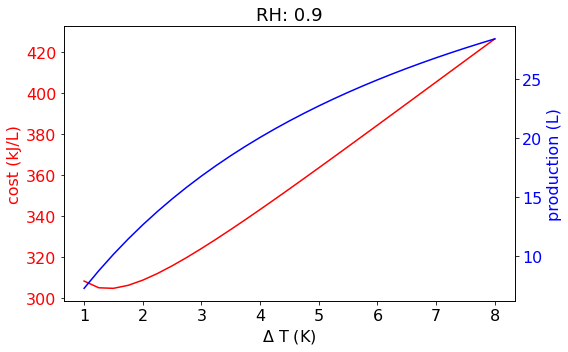

In [2]:
import matplotlib.pyplot as plt

DEFAULTS['gap']=0.005
DEFAULTS['sheet_t']=0.002
DEFAULTS['RH']=0.9
DEFAULTS['comp']=1-DEFAULTS['RH']/2


cs=[]
dl=[]
dtmp=[]
for i in range(4,33):
    dtmp.append(i/4)
    DEFAULTS['dT']=i/4
    hld=simulate()
    hlda=airflow_work()
    cs.append((hld['W_net']+hlda['work_J'])/hld['liters']/1000)
    dl.append( 2*hld['liters']/(hld['t_cycle'])*3600*24)

    
    
fig, ax1 = plt.subplots(figsize=(8, 5))
# First line (left y-axis)
ax1.plot(dtmp, cs, 'r-', label='Line 1')
ax1.set_xlabel('$\Delta$ T (K)', fontsize=16)
ax1.set_ylabel('cost (kJ/L)', color='r', fontsize=16)
ax1.tick_params(axis='y', labelcolor='r')
ax1.tick_params(axis='both', labelsize=16)
# Second line (right y-axis)a
ax2 = ax1.twinx()
ax2.plot(dtmp, dl, 'b-', label='Line 2')
ax2.set_ylabel('production (L)', color='b', fontsize=16)
ax2.tick_params(axis='y', labelcolor='b')
ax2.tick_params(axis='both', labelsize=16)

plt.title('RH: '+ str(DEFAULTS['RH']), fontsize=18)
plt.tight_layout()

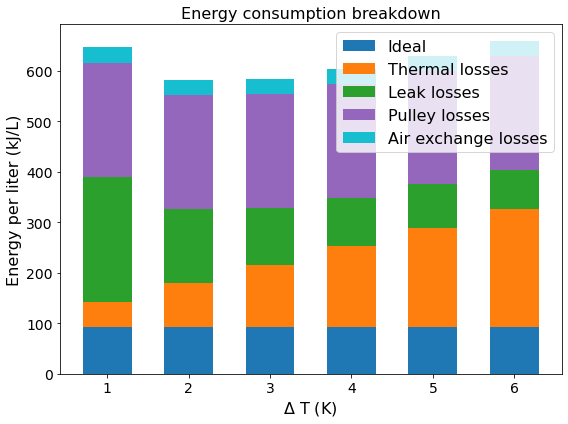

In [3]:
ids=[]
tls=[]
pls=[]
ars=[]
lks=[]
dts=[]

DEFAULTS['RH']=0.7
DEFAULTS['comp']=1-DEFAULTS['RH']/2

for i in range(0,6):
    DEFAULTS['dT']=1+i*1
    dts.append(1+i*1)
    DEFAULTS['leak_h']=0
    hlds=simulate()
    DEFAULTS['leak_h']=30e-6
    hld=simulate()
    hlda=airflow_work()
    hldi=paper_zero_loss({})
    ideal=hldi['W_net']/hldi['n_liq']/0.018/1000
    air=hlda['work_J']/hld['liters']/1000
    pulley=hld['W_exp']*(1-DEFAULTS['eff'])/hld['liters']/1000
    lk=hld['kJ_per_L']-hlds['kJ_per_L']
    tl=(hld['W_net']-hld['W_exp']*(1-DEFAULTS['eff'])-hldi['W_net']/hldi['n_liq']/0.018*hld['liters'])/hld['liters']/1000-lk
    ids.append(ideal)
    tls.append(tl)
    lks.append(lk)
    pls.append(pulley)
    ars.append(air)

    #print('minimum: ', ideal)
    #print('tl: ', tl)
    #print('leak: ', lk)
    #print('pulley: ', pulley)
    #print('air: ', air)
    #print('total: ',(hld['W_net']+hlda['work_J'])/hld['liters']/1000, (ideal+tl+lk+pulley+air))


import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(8, 6))
ax.tick_params(axis='both', labelsize=14)
width = 0.6

# Plot the base layer
ax.bar(dts, ids, width=width, label='Ideal', color='#1f77b4')

# Plot second layer
ax.bar(dts, tls, width=width, bottom=ids, label='Thermal losses', color='#ff7f0e')

# Plot third layer
ax.bar(dts, lks, width=width,
       bottom=np.array(ids) + np.array(tls),
       label='Leak losses', color='#2ca02c')

# Plot third layer
ax.bar(dts, pls, width=width,
       bottom=np.array(ids) + np.array(tls) + np.array(lks),
       label='Pulley losses', color='#9467bd')

# Plot third layer
ax.bar(dts, ars, width=width,
       bottom=np.array(ids) + np.array(tls) + np.array(lks) + np.array(pls),
       label='Air exchange losses', color='#17becf')

# Customization
ax.set_xlabel('$\Delta$ T (K)', fontsize=16)
ax.set_ylabel('Energy per liter (kJ/L)', fontsize=16)
ax.set_title('Energy consumption breakdown', fontsize=16)
ax.set_xticks(dts)
ax.legend(loc='upper right', fontsize=16)

plt.tight_layout()
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

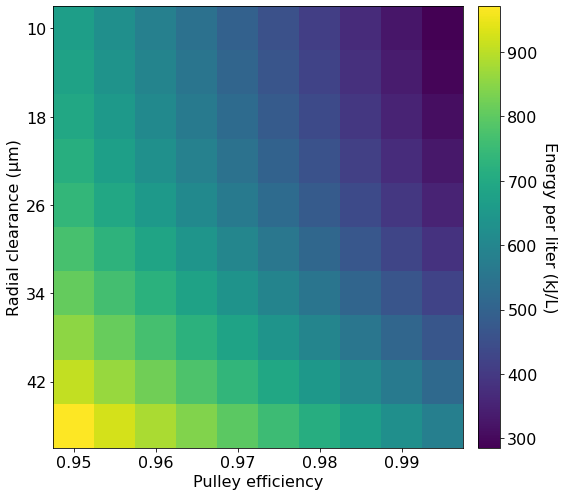

In [4]:
import matplotlib.pyplot as plt


data=[]
rows=[]
cols=[]

DEFAULTS['RH']=0.8
DEFAULTS['comp']=1-DEFAULTS['RH']/2
DEFAULTS['dT']=4

for i in range(0,10):
    DEFAULTS['leak_h']=(20+i*4)*10**(-6)
    row=[]
    rows.append(10+i*4)
    for j in range(0,10):
        DEFAULTS['eff']=0.95+j/200
        hld=simulate()
        hlda=airflow_work()
        row.append((hld['W_net']+hlda['work_J'])/hld['liters']/1000)
        if i==0:
            cols.append(0.95+j/200)
    data.append(row)
    
data=np.array(data)   

# Initialize the plot
fig, ax = plt.subplots(figsize=(8, 7))

im = ax.imshow(data, cmap="viridis", aspect="auto")

# Colorbar
cbar = fig.colorbar(im, ax=ax, pad=0.03)
cbar.ax.tick_params(labelsize=16)
cbar.ax.set_ylabel("Energy per liter (kJ/L)", rotation=-90, va="bottom", fontsize=16)

# Tick positions and labels (every other value)
ax.set_xticks(np.arange(0, len(cols), 2))
ax.set_yticks(np.arange(0, len(rows), 2))

ax.set_xticklabels([f"{x:.2f}" for x in cols[::2]], fontsize=16)
ax.set_yticklabels(rows[::2], fontsize=16)

# Axis labels
ax.set_xlabel("Pulley efficiency", fontsize=16)
ax.set_ylabel("Radial clearance (μm)", fontsize=16)

plt.tight_layout()
plt.show